In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
import re
import string


In [1]:
import os

print(os.listdir("/content"))


['.config', 'sample_data']


In [ ]:
df_fake = pd.read_csv("../input/fake-news-detection/Fake.csv")
df_true = pd.read_csv("../input/fake-news-detection/True.csv")

FileNotFoundError: [Errno 2] No such file or directory: '../input/fake-news-detection/Fake.csv'

In [2]:
import os

print(os.listdir("/content"))

['.config', 'True.csv', 'Fake.csv', 'sample_data']


In [3]:
import pandas as pd
import numpy as np
import re

df_fake = pd.read_csv("/content/Fake.csv")
df_true = pd.read_csv("/content/True.csv")

df_fake["label"] = 0
df_true["label"] = 1

df = pd.concat([df_fake, df_true], ignore_index=True)

print("Total fake news:", len(df_fake))
print("Total real news:", len(df_true))
print("\nDataset columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

Total fake news: 23481
Total real news: 21417

Dataset columns:
['title', 'text', 'subject', 'date', 'label']

First 5 rows:
                                               title  \
0   Donald Trump Sends Out Embarrassing New Year’...   
1   Drunk Bragging Trump Staffer Started Russian ...   
2   Sheriff David Clarke Becomes An Internet Joke...   
3   Trump Is So Obsessed He Even Has Obama’s Name...   
4   Pope Francis Just Called Out Donald Trump Dur...   

                                                text subject  \
0  Donald Trump just couldn t wish all Americans ...    News   
1  House Intelligence Committee Chairman Devin Nu...    News   
2  On Friday, it was revealed that former Milwauk...    News   
3  On Christmas day, Donald Trump announced that ...    News   
4  Pope Francis used his annual Christmas Day mes...    News   

                date  label  
0  December 31, 2017      0  
1  December 31, 2017      0  
2  December 30, 2017      0  
3  December 29, 2017      0  
4  

In [4]:
fake_sample = df_fake.sample(
    n=min(1000, len(df_fake)),
    random_state=42
)

real_sample = df_true.sample(
    n=min(1000, len(df_true)),
    random_state=42
)

df = pd.concat(
    [fake_sample, real_sample],
    ignore_index=True
)

df = df[["title", "text", "label"]]

print("Selected dataset shape:", df.shape)
print("\nLabel distribution:")
print(df["label"].value_counts())

Selected dataset shape: (2000, 3)

Label distribution:
label
0    1000
1    1000
Name: count, dtype: int64


In [5]:
df["title"] = df["title"].fillna("")
df["text"] = df["text"].fillna("")

df["news"] = df["title"] + " " + df["text"]

df = df.dropna(subset=["label"])
df = df[df["news"].str.strip() != ""]
df = df.drop_duplicates(subset=["news"]).reset_index(drop=True)

print("Missing values:")
print(df[["title", "text", "label"]].isnull().sum())

print("\nFinal dataset shape:", df.shape)

Missing values:
title    0
text     0
label    0
dtype: int64

Final dataset shape: (1992, 4)


In [6]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["news"] = df["news"].apply(clean_text)

print(df[["news", "label"]].head())

                                                news  label
0  about hillary s cough we discovered the secret...      0
1  breaking obamacare repeal clears first hurdle ...      0
2  sleepy justice ginsburg excites crowd by sayin...      0
3  watch kellyanne conway very upset hillary clin...      0
4  gop gives trump the middle finger prepares to ...      0


In [7]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["news"],
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

print("Training articles:", len(X_train_text))
print("Testing articles:", len(X_test_text))

Training articles: 1593
Testing articles: 399


In [8]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

tokenizer = Tokenizer(
    num_words=10000,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

X_train = pad_sequences(
    X_train_seq,
    maxlen=200,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test_seq,
    maxlen=200,
    padding="post",
    truncating="post"
)

y_train = np.array(y_train)
y_test = np.array(y_test)

print("Training sequence shape:", X_train.shape)
print("Testing sequence shape:", X_test.shape)

Training sequence shape: (1593, 200)
Testing sequence shape: (399, 200)


In [9]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential([
    Embedding(input_dim=10000, output_dim=64),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [10]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 142ms/step - accuracy: 0.5502 - loss: 0.6848 - val_accuracy: 0.5643 - val_loss: 0.6761
Epoch 2/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 99ms/step - accuracy: 0.7057 - loss: 0.6351 - val_accuracy: 0.7429 - val_loss: 0.5181
Epoch 3/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 132ms/step - accuracy: 0.8980 - loss: 0.2967 - val_accuracy: 0.8746 - val_loss: 0.3466
Epoch 4/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 98ms/step - accuracy: 0.9223 - loss: 0.2898 - val_accuracy: 0.8589 - val_loss: 0.3940
Epoch 5/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 98ms/step - accuracy: 0.9152 - loss: 0.2491 - val_accuracy: 0.9122 - val_loss: 0.3082


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_prob = model.predict(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-Score:", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Fake", "Real"],
    zero_division=0
))

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step
Accuracy: 0.9022556390977443
Precision: 0.8888888888888888
Recall: 0.92
F1-Score: 0.9041769041769042

Classification Report:
              precision    recall  f1-score   support

        Fake       0.92      0.88      0.90       199
        Real       0.89      0.92      0.90       200

    accuracy                           0.90       399
   macro avg       0.90      0.90      0.90       399
weighted avg       0.90      0.90      0.90       399



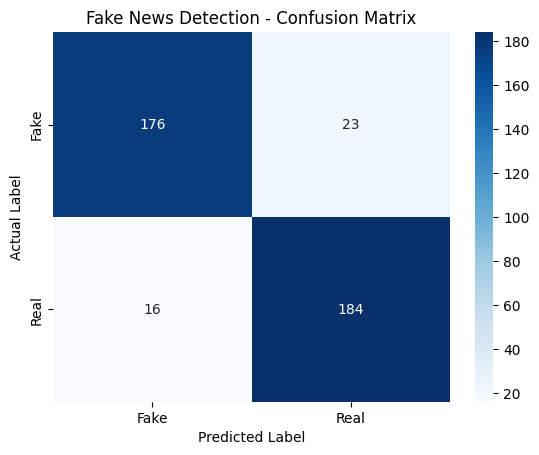

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Fake News Detection - Confusion Matrix")
plt.show()

In [13]:
def predict_news(news_text):
    cleaned = clean_text(news_text)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=200,
        padding="post",
        truncating="post"
    )

    probability = float(model.predict(padded, verbose=0)[0][0])

    prediction = "Real" if probability >= 0.5 else "Fake"

    print("Predicted category:", prediction)
    print(f"Model score for Real: {probability:.2%}")
    print("Note: This is a model prediction, not verified fact-checking.")

predict_news(
    "The government announced a new public transportation project today."
)

Predicted category: Real
Model score for Real: 93.34%
Note: This is a model prediction, not verified fact-checking.
